## 0. Setup

### 0.1 Install required packages

In [1]:
# Cell: Install required packages

import sys
import subprocess

REQUIRED_PACKAGES = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "xgboost",
    "shap",
    "networkx",
    "joblib",
    "openai",      # Optional_External_E; to be used later for the Negotiation Assistant's advice-generation step
]

for package in REQUIRED_PACKAGES:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

print("All required packages installed.")


All required packages installed.


In [47]:
import sys
import sklearn
import numpy

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
scikit-learn: 1.7.2
NumPy: 2.3.5


In [2]:
# Cell: Imports and global settings

import os
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from xgboost import XGBRegressor
import shap
import networkx as nx
import joblib

warnings.filterwarnings("ignore")

# ---- Reproducibility ----
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# ---- Display / plotting settings ----
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Imports complete. Random seed fixed at", RANDOM_STATE)


Imports complete. Random seed fixed at 42


## 1. Data Loading



In [3]:
# Cell: Load the dataset

CANDIDATE_PATHS = [r"C:\Users\valen\PycharmProjects\PayHerRight_System\nigeria_tech_salary.csv",
    "nigeria_tech_salary_synthetic_v2.csv"]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Put nigeria_tech_salary.csv in the same folder as this notebook "
        f"(current folder: {os.getcwd()})."
    )

df = pd.read_csv(DATA_PATH)

EXPECTED_COLUMNS = [
    "employee_id", "gender", "age", "years_experience", "years_current_company",
    "education", "job_category", "job_title", "location", "company_size",
    "remote_ratio", "skills", "num_skills", "certifications",
    "annual_salary_ngn", "annual_salary_usd_approx",
]
missing_cols = [c for c in EXPECTED_COLUMNS if c not in df.columns]
if missing_cols:
    raise ValueError(f"The CSV is missing expected columns: {missing_cols}")

print(f"Loaded {DATA_PATH} with shape: {df.shape}")
if df.shape != (8000, 16):
    print("NOTE: the reference dataset has 8,000 rows and 16 columns. Your file differs, "
          "so your results will differ slightly from the reference results.")
df.head()


Loaded C:\Users\valen\PycharmProjects\PayHerRight_System\nigeria_tech_salary.csv with shape: (8000, 16)


,employee_id,gender,age,years_experience,years_current_company,education,job_category,job_title,location,company_size,remote_ratio,skills,num_skills,certifications,annual_salary_ngn,annual_salary_usd_approx
0,1,Male,35,13,0,BSc,Software Engineering,Backend Developer,Port Harcourt,Startup (<50 employees),0,"React, Spring Boot, Java, Python, Kotlin",5,1,4200000,3065.69
1,2,Male,33,12,2,HND,Web Development,WordPress Developer,Lagos,Startup (<50 employees),50,"HTML/CSS, Git, JavaScript",3,1,2900000,2116.79
2,3,Male,28,3,0,HND,Data Science,Data Analyst,Abuja,Medium (50-250 employees),0,"Statistics, Excel, Power BI, Pandas",4,1,2270000,1656.93
3,4,Male,28,5,2,HND,DevOps,Cloud Engineer,Abuja,Startup (<50 employees),100,"Kubernetes, Azure, Linux",3,0,2670000,1948.91
4,5,Male,22,1,0,BSc,Product Management,Product Manager,Remote (International Client),Large (250+ employees),50,"Figma, Scrum, Agile, Roadmapping",4,1,12110000,8839.42


## 2. Exploratory Data Analysis (EDA)

In [4]:
# Cell: Basic structure check
print("Shape:", df.shape)
print("\nColumn dtypes:\n", df.dtypes)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nNumeric summary statistics:\n")
df.describe().T


Shape: (8000, 16)

Column dtypes:
 employee_id                   int64
gender                       object
age                           int64
years_experience              int64
years_current_company         int64
education                    object
job_category                 object
job_title                    object
location                     object
company_size                 object
remote_ratio                  int64
skills                       object
num_skills                    int64
certifications                int64
annual_salary_ngn             int64
annual_salary_usd_approx    float64
dtype: object

Missing values per column:
 employee_id                 0
gender                      0
age                         0
years_experience            0
years_current_company       0
education                   0
job_category                0
job_title                   0
location                    0
company_size                0
remote_ratio                0
skills          

,count,mean,std,min,25%,50%,75%,max
employee_id,8000.0,4.000500e+03,2.309545e+03,1.00,2000.75,4000.50,6000.25,8000.0
age,8000.0,2.673763e+01,4.448371e+00,20.00,24.00,26.00,29.00,47.0
years_experience,8000.0,4.242625e+00,4.115717e+00,0.00,1.00,3.00,6.00,22.0
years_current_company,8000.0,1.322375e+00,1.384897e+00,0.00,0.00,1.00,2.00,14.0
remote_ratio,8000.0,4.015625e+01,4.068777e+01,0.00,0.00,50.00,100.00,100.0
num_skills,8000.0,4.486375e+00,1.121259e+00,3.00,3.00,4.00,5.00,6.0
certifications,8000.0,1.089750e+00,1.047059e+00,0.00,0.00,1.00,2.00,7.0
annual_salary_ngn,8000.0,4.374092e+06,3.461996e+06,960000.00,2580000.00,3340000.00,4550000.00,42530000.0
annual_salary_usd_approx,8000.0,3.192768e+03,2.527005e+03,700.73,1883.21,2437.96,3321.17,31043.8


In [5]:
# Cell: Define consistent category orderings ONCE, reused across every plot below.
# (Just remember Max dt Defining these in one place avoids a subtle bug where different plots use
# slightly different spellings/orderings for the same categorical values go mean wahala uche gi di ya.)

EDUCATION_ORDER = ["OND", "HND", "BSc", "MSc", "PhD", "Bootcamp/Certification"]
LOCATION_ORDER = ["Lagos", "Abuja", "Port Harcourt", "Ibadan", "Enugu", "Kano",
                   "Remote (International Client)"]
COMPANY_SIZE_ORDER = ["Startup (<50 employees)", "Medium (50-250 employees)",
                       "Large (250+ employees)"]
JOB_CATEGORY_ORDER = sorted(df["job_category"].unique())
GENDER_ORDER = ["Male", "Female"]

print("Category orderings defined:")
print(" education:", EDUCATION_ORDER)
print(" location:", LOCATION_ORDER)
print(" company_size:", COMPANY_SIZE_ORDER)


Category orderings defined:
 education: ['OND', 'HND', 'BSc', 'MSc', 'PhD', 'Bootcamp/Certification']
 location: ['Lagos', 'Abuja', 'Port Harcourt', 'Ibadan', 'Enugu', 'Kano', 'Remote (International Client)']
 company_size: ['Startup (<50 employees)', 'Medium (50-250 employees)', 'Large (250+ employees)']


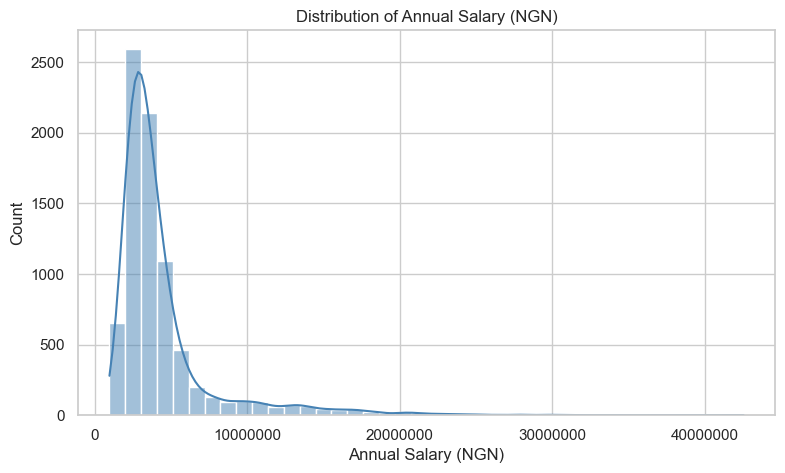

In [6]:
# Cell: Salary distribution (overall)
plt.figure(figsize=(9, 5))
sns.histplot(df["annual_salary_ngn"], kde=True, color="steelblue", bins=40)
plt.title("Distribution of Annual Salary (NGN)")
plt.xlabel("Annual Salary (NGN)")
plt.ylabel("Count")
plt.ticklabel_format(style="plain", axis="x")
plt.show()


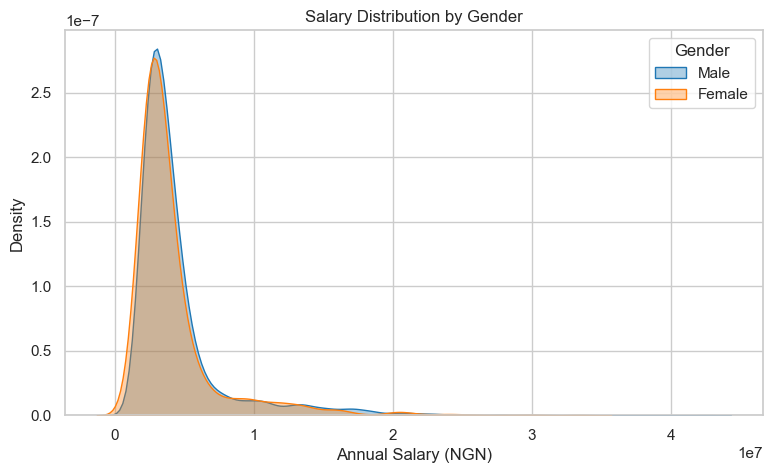

         count          mean        50%           std
gender                                               
Female  1647.0  4.181548e+06  3130000.0  3.470748e+06
Male    6353.0  4.424009e+06  3390000.0  3.458248e+06


In [7]:
# Cell: Salary distribution split by gender -- the key EDA plot for this thesis
plt.figure(figsize=(9, 5))
for gender, color in zip(GENDER_ORDER, ["tab:blue", "tab:orange"]):
    subset = df[df["gender"] == gender]["annual_salary_ngn"]
    sns.kdeplot(subset, fill=True, alpha=0.35, label=gender, color=color)
plt.title("Salary Distribution by Gender")
plt.xlabel("Annual Salary (NGN)")
plt.legend(title="Gender")
plt.show()

# Quick numeric summary alongside the plot
print(df.groupby("gender")["annual_salary_ngn"].describe()[["count", "mean", "50%", "std"]])


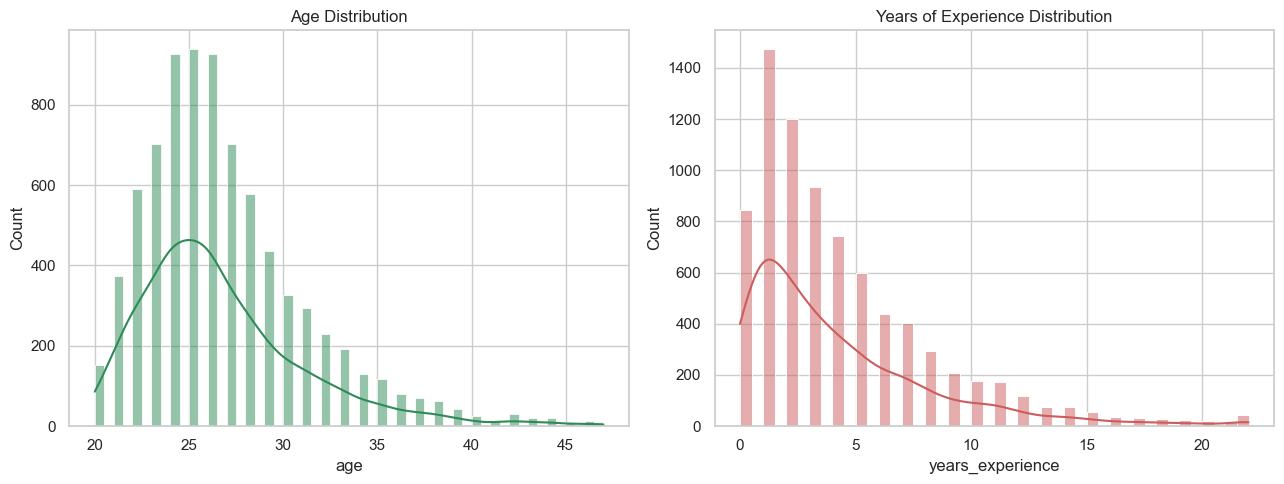

In [8]:
# Cell: Age and years-of-experience distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["age"], kde=True, ax=axes[0], color="seagreen")
axes[0].set_title("Age Distribution")

sns.histplot(df["years_experience"], kde=True, ax=axes[1], color="indianred")
axes[1].set_title("Years of Experience Distribution")

plt.tight_layout()
plt.show()


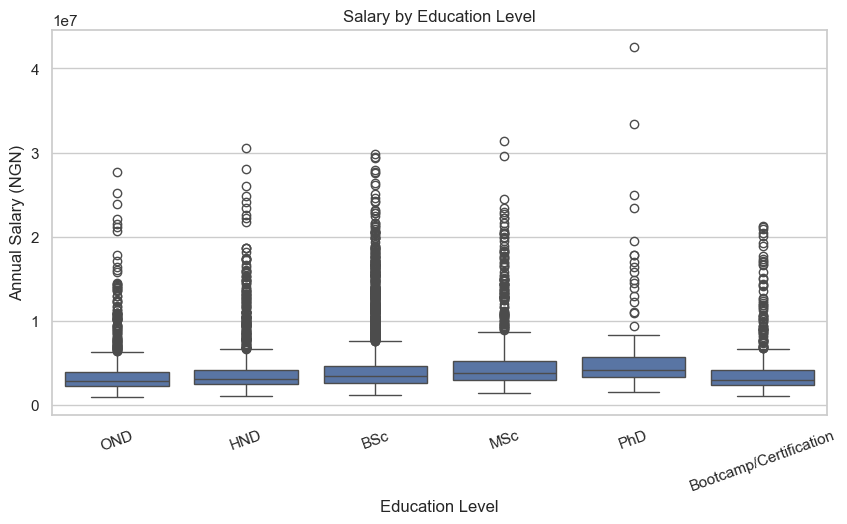

In [9]:
# Cell: Salary by education level (boxplot)
plt.figure(figsize=(10, 5))
sns.boxplot(x="education", y="annual_salary_ngn", data=df, order=EDUCATION_ORDER)
plt.title("Salary by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Annual Salary (NGN)")
plt.xticks(rotation=20)
plt.show()


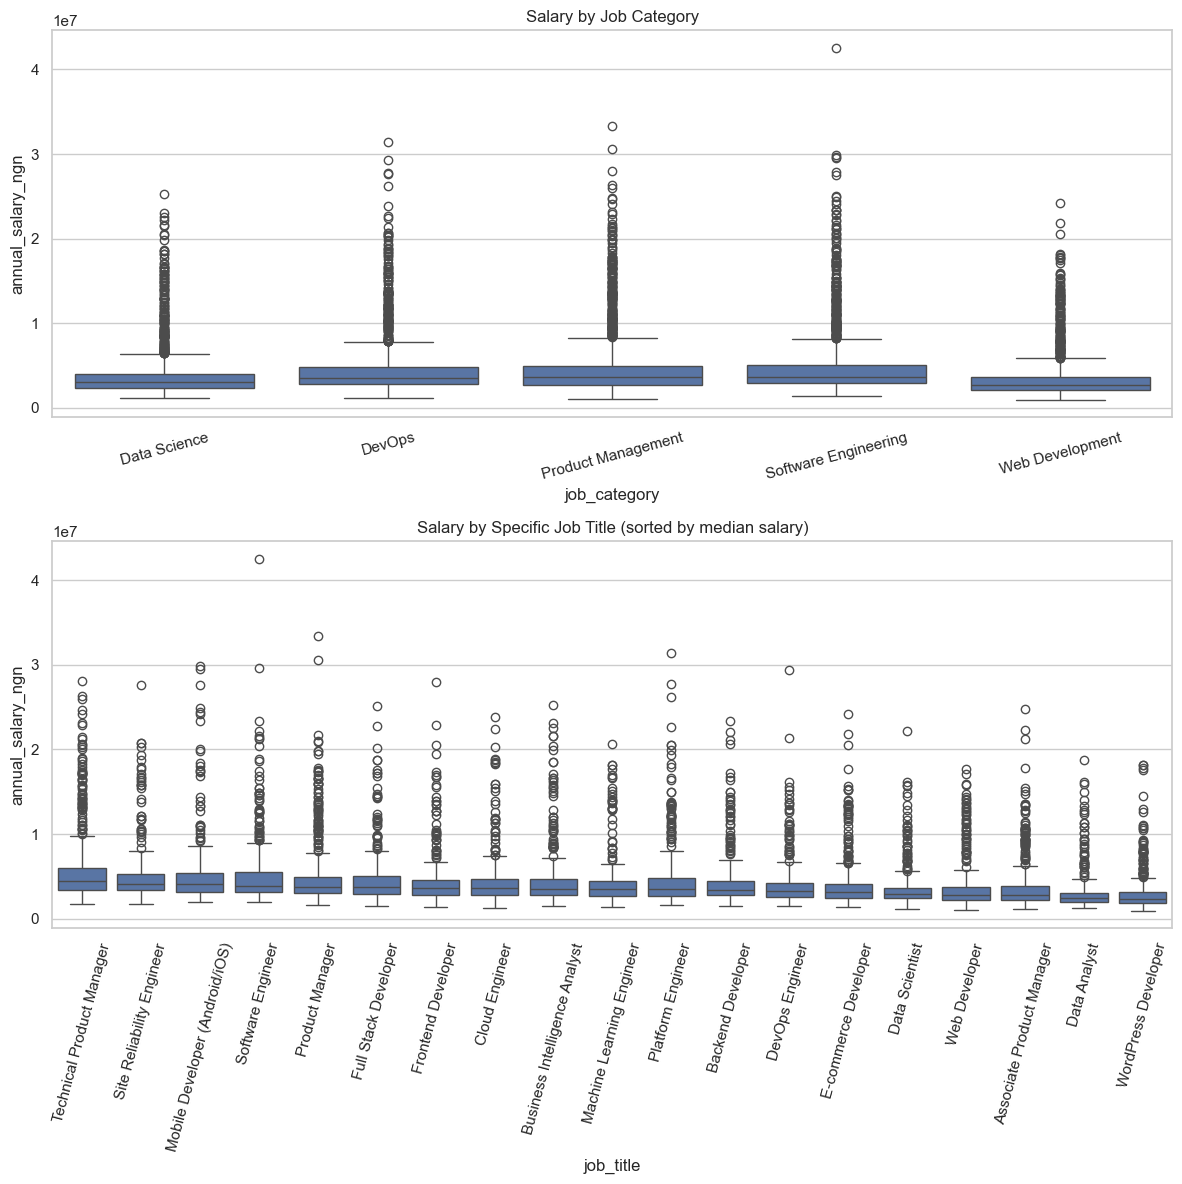

In [10]:
# Cell: Salary by job category and job title (boxplots)
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

sns.boxplot(x="job_category", y="annual_salary_ngn", data=df,
            order=JOB_CATEGORY_ORDER, ax=axes[0])
axes[0].set_title("Salary by Job Category")
axes[0].tick_params(axis="x", rotation=15)

job_title_order = df.groupby("job_title")["annual_salary_ngn"].median().sort_values(ascending=False).index
sns.boxplot(x="job_title", y="annual_salary_ngn", data=df,
            order=job_title_order, ax=axes[1])
axes[1].set_title("Salary by Specific Job Title (sorted by median salary)")
axes[1].tick_params(axis="x", rotation=75)

plt.tight_layout()
plt.show()


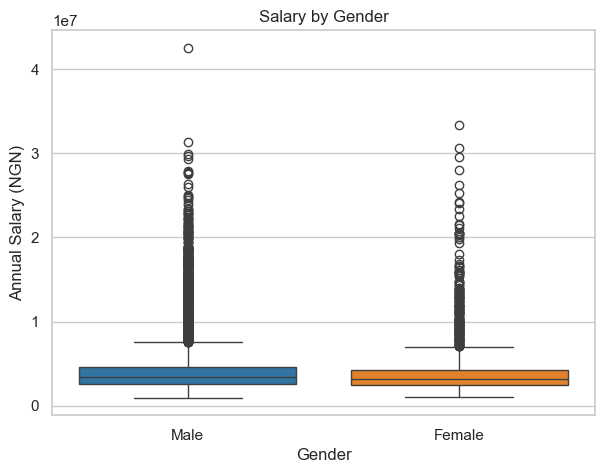

Male mean salary:   NGN 4,424,009
Female mean salary: NGN 4,181,548
Raw (unadjusted) gender pay gap: 5.48%


In [11]:
# Cell: Salary by gender -- boxplot version (companion to the KDE plot above)
plt.figure(figsize=(7, 5))
sns.boxplot(x="gender", y="annual_salary_ngn", data=df, order=GENDER_ORDER,
            palette=["tab:blue", "tab:orange"])
plt.title("Salary by Gender")
plt.xlabel("Gender")
plt.ylabel("Annual Salary (NGN)")
plt.show()

male_mean = df[df["gender"] == "Male"]["annual_salary_ngn"].mean()
female_mean = df[df["gender"] == "Female"]["annual_salary_ngn"].mean()
raw_gap_pct = (1 - female_mean / male_mean) * 100
print(f"Male mean salary:   NGN {male_mean:,.0f}")
print(f"Female mean salary: NGN {female_mean:,.0f}")
print(f"Raw (unadjusted) gender pay gap: {raw_gap_pct:.2f}%")


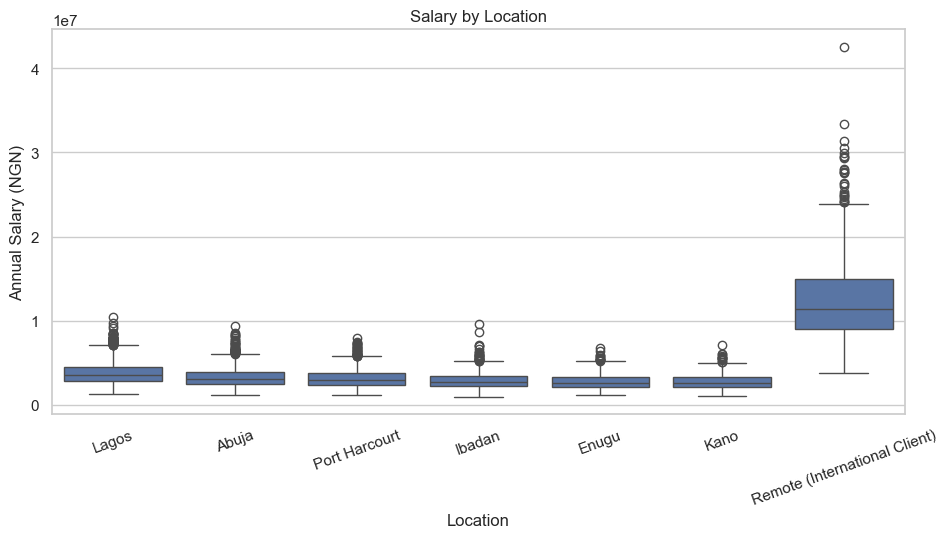

In [12]:
# Cell: Salary by location (confirms the Lagos/Abuja/Remote premiums baked into the data)
plt.figure(figsize=(11, 5))
sns.boxplot(x="location", y="annual_salary_ngn", data=df, order=LOCATION_ORDER)
plt.title("Salary by Location")
plt.xlabel("Location")
plt.ylabel("Annual Salary (NGN)")
plt.xticks(rotation=20)
plt.show()


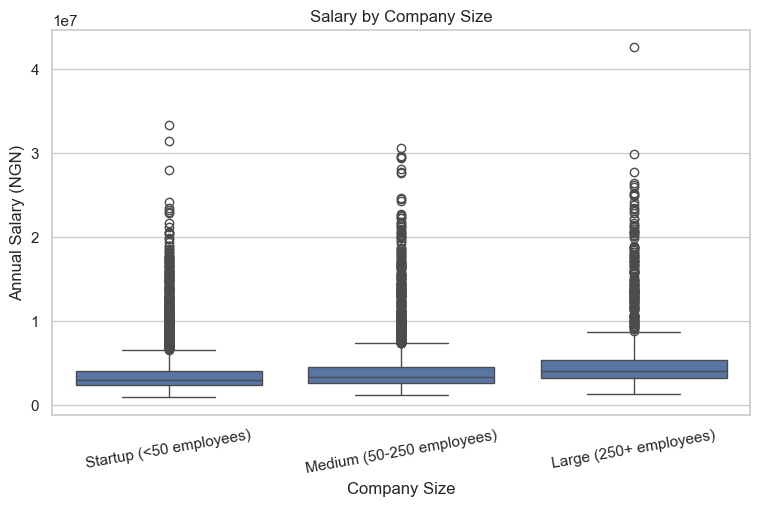

In [13]:
# Cell: Salary by company size
plt.figure(figsize=(9, 5))
sns.boxplot(x="company_size", y="annual_salary_ngn", data=df, order=COMPANY_SIZE_ORDER)
plt.title("Salary by Company Size")
plt.xlabel("Company Size")
plt.ylabel("Annual Salary (NGN)")
plt.xticks(rotation=10)
plt.show()


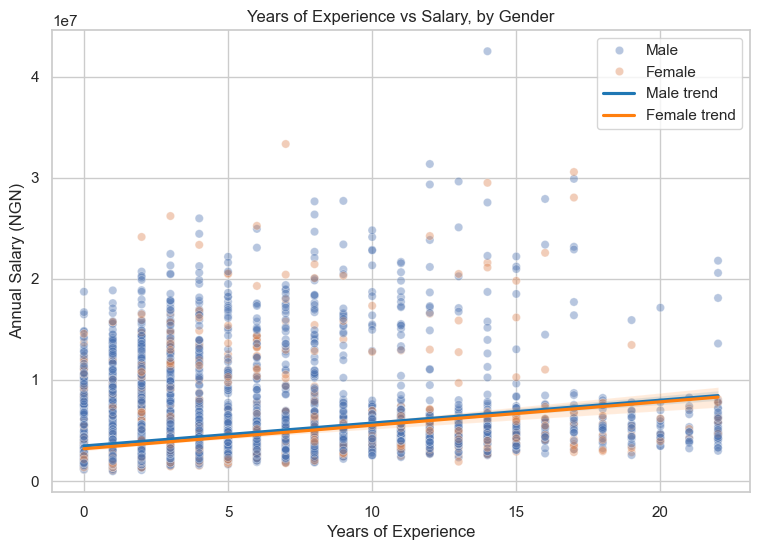

In [14]:
# Cell: Years of experience vs salary, colored by gender
# Lets me see visually whether the gender gap holds across experience levels,
# not just in the aggregate boxplot above.
plt.figure(figsize=(9, 6))
sns.scatterplot(x="years_experience", y="annual_salary_ngn", hue="gender",
                 data=df, alpha=0.4, hue_order=GENDER_ORDER)
sns.regplot(x="years_experience", y="annual_salary_ngn",
            data=df[df["gender"] == "Male"], scatter=False, color="tab:blue", label="Male trend")
sns.regplot(x="years_experience", y="annual_salary_ngn",
            data=df[df["gender"] == "Female"], scatter=False, color="tab:orange", label="Female trend")
plt.title("Years of Experience vs Salary, by Gender")
plt.xlabel("Years of Experience")
plt.ylabel("Annual Salary (NGN)")
plt.legend()
plt.show()


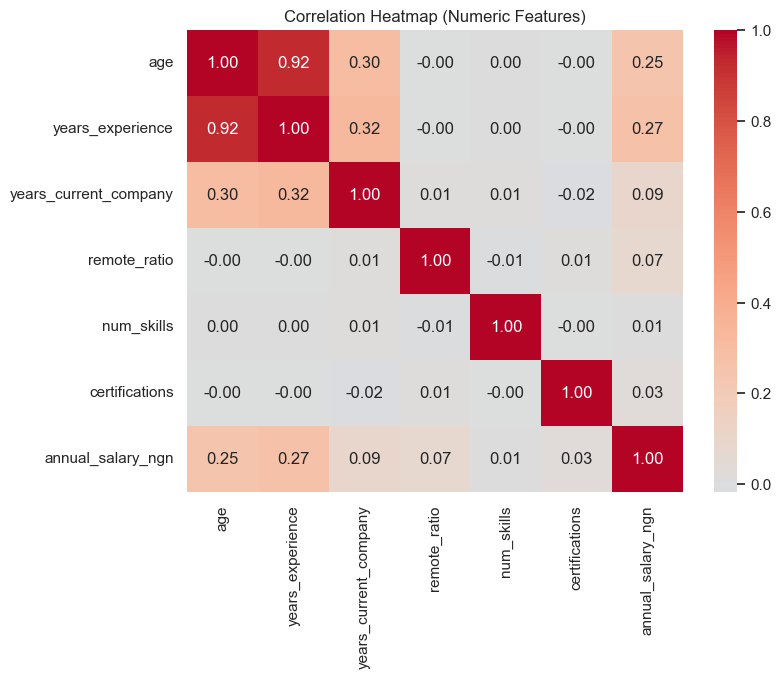

In [15]:
# Cell: Correlation heatmap for numeric features
numeric_cols_for_corr = ["age", "years_experience", "years_current_company",
                          "remote_ratio", "num_skills", "certifications",
                          "annual_salary_ngn"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols_for_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()


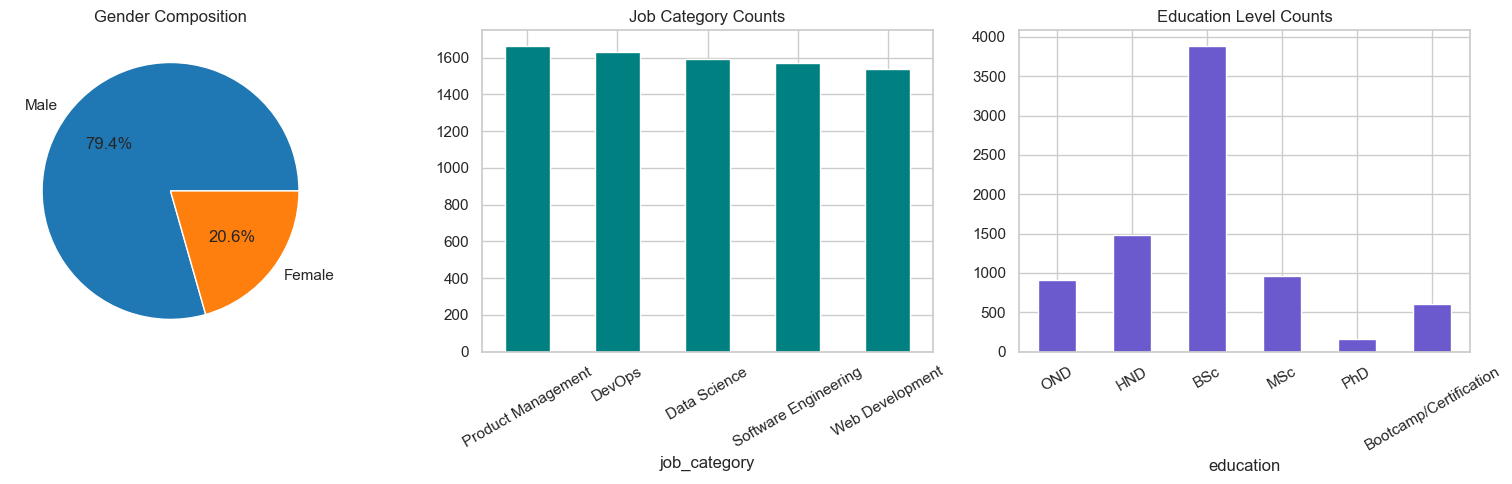

In [16]:
# Cell: Categorical composition -- how the sample is distributed
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

df["gender"].value_counts().reindex(GENDER_ORDER).plot(
    kind="pie", autopct="%1.1f%%", ax=axes[0], colors=["tab:blue", "tab:orange"])
axes[0].set_title("Gender Composition")
axes[0].set_ylabel("")

df["job_category"].value_counts().plot(kind="bar", ax=axes[1], color="teal")
axes[1].set_title("Job Category Counts")
axes[1].tick_params(axis="x", rotation=30)

df["education"].value_counts().reindex(EDUCATION_ORDER).plot(kind="bar", ax=axes[2], color="slateblue")
axes[2].set_title("Education Level Counts")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


## 3. Data Preprocessing

`gender` is deliberately kept as an input feature. This is intentional, not an oversight: the
Bias Detector in Section 5 needs the model to actually be able to use gender internally so that
SHAP can measure how much weight it gives that feature versus legitimate factors (experience,
education, role, etc.).


In [17]:
# Cell: Define features and target
TARGET = "annual_salary_ngn"

# Columns dropped from modelling: employee_id (identifier, not predictive),
# skills (free text -- num_skills already captures the useful signal),
# annual_salary_usd_approx (a derived duplicate of the target, would leak).
DROP_COLS = ["employee_id", "skills", "annual_salary_usd_approx"]

model_df = df.drop(columns=DROP_COLS)

X = model_df.drop(columns=[TARGET])
y = model_df[TARGET]

NUMERIC_FEATURES = ["age", "years_experience", "years_current_company",
                     "remote_ratio", "num_skills", "certifications"]
CATEGORICAL_FEATURES = ["gender", "education", "job_category", "job_title",
                         "location", "company_size"]

assert set(NUMERIC_FEATURES + CATEGORICAL_FEATURES) == set(X.columns), \
    "Feature lists do not match the columns in X -- check for typos."

print("Numeric features:", NUMERIC_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)
print("Target:", TARGET)


Numeric features: ['age', 'years_experience', 'years_current_company', 'remote_ratio', 'num_skills', 'certifications']
Categorical features: ['gender', 'education', 'job_category', 'job_title', 'location', 'company_size']
Target: annual_salary_ngn


In [18]:
# Cell: Build the preprocessing pipeline
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, NUMERIC_FEATURES),
    ("cat", categorical_transformer, CATEGORICAL_FEATURES),
])

print("Preprocessor built: median-impute+scale for numeric, mode-impute+one-hot for categorical.")


Preprocessor built: median-impute+scale for numeric, mode-impute+one-hot for categorical.


In [19]:
# Cell: Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (6400, 12)
Test shape: (1600, 12)


## 4. Model Training — Ensemble Learning (Random Forest & XGBoost)

In [20]:
# Cell: Shared evaluation helper, used for every model below
def regression_metrics(y_true, y_pred):
    """Return RMSE, MAE, and R^2 for a set of predictions."""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"RMSE": rmse, "MAE": mae, "R2": r2}

def print_metrics(name, metrics):
    print(f"\n{name} performance:")
    for k, v in metrics.items():
        print(f"  {k}: {v:,.4f}")


In [21]:
# Cell: Random Forest Regressor, tuned with GridSearchCV
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
])

rf_param_grid = {
    "regressor__n_estimators": [150, 250],
    "regressor__max_depth": [None, 15, 25],
    "regressor__min_samples_split": [2, 5],
}

grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=3,
    n_jobs=-1,
    scoring="r2",
    verbose=1,
)

grid_search_rf.fit(X_train, y_train)
best_rf = grid_search_rf.best_estimator_

print("\nBest Random Forest parameters:", grid_search_rf.best_params_)

y_pred_rf = best_rf.predict(X_test)
metrics_rf = regression_metrics(y_test, y_pred_rf)
print_metrics("Random Forest", metrics_rf)


Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best Random Forest parameters: {'regressor__max_depth': None, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 250}

Random Forest performance:
  RMSE: 1,330,036.3469
  MAE: 665,825.0797
  R2: 0.8716


In [22]:
# Cell: XGBoost Regressor, tuned with GridSearchCV
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(random_state=RANDOM_STATE, objective="reg:squarederror")),
])

xgb_param_grid = {
    "regressor__n_estimators": [150, 250],
    "regressor__max_depth": [4, 6],
    "regressor__learning_rate": [0.05, 0.1],
}

grid_search_xgb = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=3,
    n_jobs=-1,
    scoring="r2",
    verbose=1,
)

grid_search_xgb.fit(X_train, y_train)
best_xgb = grid_search_xgb.best_estimator_

print("\nBest XGBoost parameters:", grid_search_xgb.best_params_)

y_pred_xgb = best_xgb.predict(X_test)
metrics_xgb = regression_metrics(y_test, y_pred_xgb)
print_metrics("XGBoost", metrics_xgb)


Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best XGBoost parameters: {'regressor__learning_rate': 0.05, 'regressor__max_depth': 4, 'regressor__n_estimators': 250}

XGBoost performance:
  RMSE: 1,229,191.8309
  MAE: 587,519.7500
  R2: 0.8903


### 4.1 Combining Random Forest and XGBoost into one ensemble prediction


In [23]:
# Cell: Out-of-fold predictions for both tuned models (training set only)
from sklearn.model_selection import cross_val_predict

oof_rf = cross_val_predict(best_rf, X_train, y_train, cv=5, n_jobs=-1)
oof_xgb = cross_val_predict(best_xgb, X_train, y_train, cv=5, n_jobs=-1)

print("Out-of-fold predictions computed for both tuned models on the training set.")


Out-of-fold predictions computed for both tuned models on the training set.


In [24]:
# Cell: Weight search -- unconstrained (reported for transparency only)
best_w_unconstrained, best_r2_unconstrained = None, -np.inf
for w_rf in np.arange(0.0, 1.01, 0.05):
    blended = w_rf * oof_rf + (1 - w_rf) * oof_xgb
    r2 = r2_score(y_train, blended)
    if r2 > best_r2_unconstrained:
        best_r2_unconstrained, best_w_unconstrained = r2, w_rf

print(f"Unconstrained optimum: RF weight={best_w_unconstrained:.2f}, "
      f"XGBoost weight={1 - best_w_unconstrained:.2f} (out-of-fold R2={best_r2_unconstrained:.4f})")
print("(If this comes out near RF=0.00, it means XGBoost alone is the pure-accuracy-optimal")
print(" choice here -- an honest finding, reported rather than hidden.)")

# Cell: Weight search -- constrained so BOTH models keep at least 25% of the weight,
# matching the system design's requirement that both genuinely contribute
best_w, best_r2_oof = None, -np.inf
for w_rf in np.arange(0.25, 0.76, 0.05):
    blended = w_rf * oof_rf + (1 - w_rf) * oof_xgb
    r2 = r2_score(y_train, blended)
    if r2 > best_r2_oof:
        best_r2_oof, best_w = r2, w_rf

W_RF, W_XGB = best_w, 1 - best_w
print(f"\nConstrained (production) weights: RF={W_RF:.2f}, XGBoost={W_XGB:.2f} "
      f"(out-of-fold R2={best_r2_oof:.4f})")


Unconstrained optimum: RF weight=0.00, XGBoost weight=1.00 (out-of-fold R2=0.8923)
(If this comes out near RF=0.00, it means XGBoost alone is the pure-accuracy-optimal
 choice here -- an honest finding, reported rather than hidden.)

Constrained (production) weights: RF=0.25, XGBoost=0.75 (out-of-fold R2=0.8910)


In [25]:
# Cell: Build and fit the final combined ensemble with the chosen weights
from sklearn.ensemble import VotingRegressor

rf_tuned_params = {k.replace("regressor__", ""): v for k, v in grid_search_rf.best_params_.items()}
xgb_tuned_params = {k.replace("regressor__", ""): v for k, v in grid_search_xgb.best_params_.items()}

rf_for_ensemble = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **rf_tuned_params)
xgb_for_ensemble = XGBRegressor(random_state=RANDOM_STATE, objective="reg:squarederror", **xgb_tuned_params)

ensemble_regressor = VotingRegressor(
    estimators=[("rf", rf_for_ensemble), ("xgb", xgb_for_ensemble)],
    weights=[W_RF, W_XGB],
)

ensemble_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("ensemble", ensemble_regressor),
])
ensemble_pipeline.fit(X_train, y_train)

y_pred_ensemble = ensemble_pipeline.predict(X_test)
metrics_ensemble = regression_metrics(y_test, y_pred_ensemble)
print_metrics(f"Combined Ensemble (RF {W_RF:.0%} + XGBoost {W_XGB:.0%})", metrics_ensemble)



Combined Ensemble (RF 25% + XGBoost 75%) performance:
  RMSE: 1,240,311.7730
  MAE: 594,569.8144
  R2: 0.8883


Model Comparison:

                                              RMSE            MAE        R2
Random Forest (alone)                 1.330036e+06  665825.079678  0.871551
XGBoost (alone)                       1.229192e+06  587519.750000  0.890291
Combined Ensemble (25% RF + 75% XGB)  1.240312e+06  594569.814422  0.888297


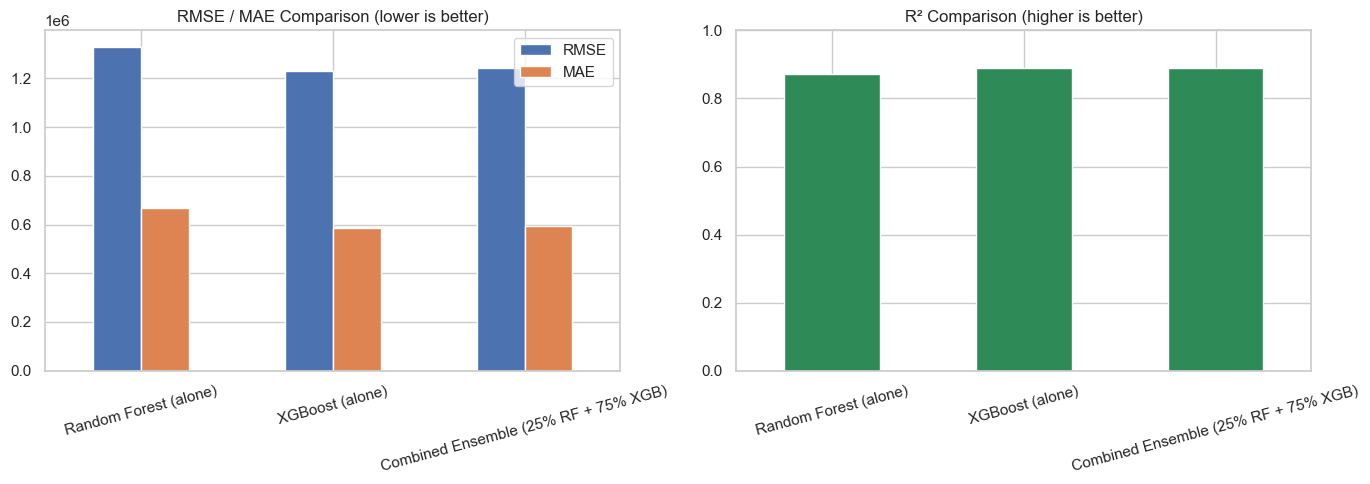


Production model: Combined Ensemble (25% Random Forest + 75% XGBoost)
(For reference, XGBoost alone scored R2=0.8903 vs the ensemble's R2=0.8883 -- the small difference is the honest cost of requiring both models to genuinely participate.)


In [26]:
# Cell: Compare Random Forest alone, XGBoost alone, and the Combined Ensemble
model_results = {
    "Random Forest (alone)": metrics_rf,
    "XGBoost (alone)": metrics_xgb,
    f"Combined Ensemble ({W_RF:.0%} RF + {W_XGB:.0%} XGB)": metrics_ensemble,
}
df_results = pd.DataFrame(model_results).T[["RMSE", "MAE", "R2"]]

print("Model Comparison:\n")
print(df_results)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_results[["RMSE", "MAE"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("RMSE / MAE Comparison (lower is better)")
axes[0].tick_params(axis="x", rotation=15)

df_results[["R2"]].plot(kind="bar", ax=axes[1], color="seagreen", legend=False)
axes[1].set_title("R\u00b2 Comparison (higher is better)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

# The combined ensemble is the production SalaryPredictor model from here on,
# per the system design's requirement that both algorithms genuinely contribute
# to the final prediction (rather than picking whichever single model scored higher).
BEST_MODEL_NAME = f"Combined Ensemble ({W_RF:.0%} Random Forest + {W_XGB:.0%} XGBoost)"
best_model = ensemble_pipeline
print(f"\nProduction model: {BEST_MODEL_NAME}")
print(f"(For reference, XGBoost alone scored R2={metrics_xgb['R2']:.4f} vs the "
      f"ensemble's R2={metrics_ensemble['R2']:.4f} -- the small difference is the "
      f"honest cost of requiring both models to genuinely participate.)")


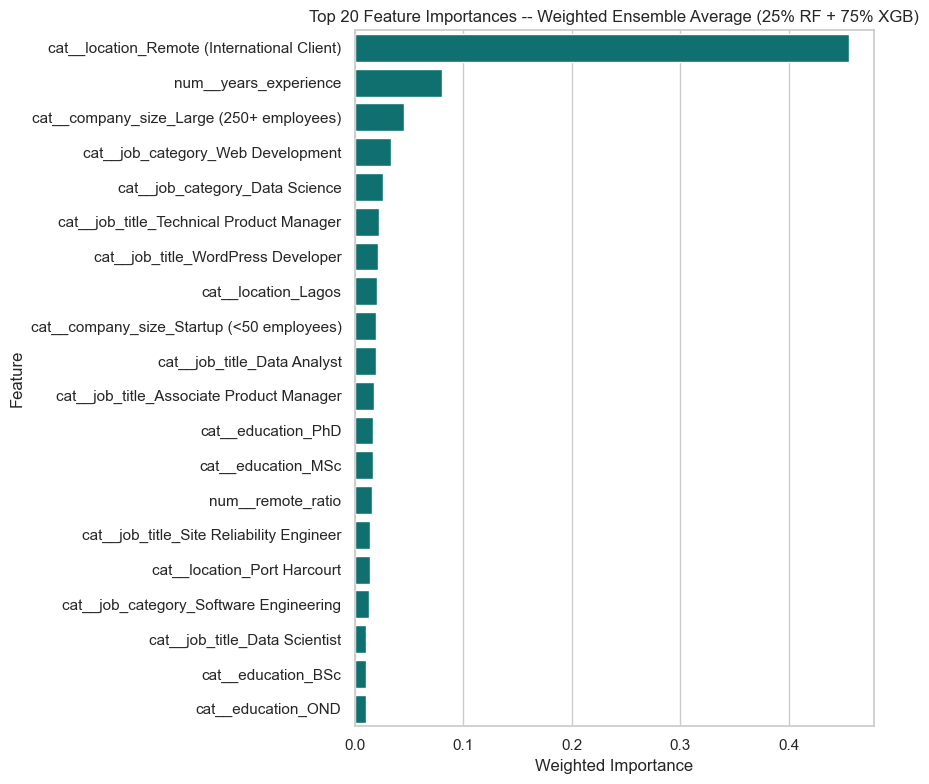

,feature,importance
44,cat__location_Remote (International Client),0.455716
1,num__years_experience,0.080658
45,cat__company_size_Large (250+ employees),0.045078
18,cat__job_category_Web Development,0.033284
14,cat__job_category_Data Science,0.025896
35,cat__job_title_Technical Product Manager,0.022798
37,cat__job_title_WordPress Developer,0.021278
42,cat__location_Lagos,0.020717
47,cat__company_size_Startup (<50 employees),0.019915
23,cat__job_title_Data Analyst,0.019821


In [27]:
# Cell: Feature importance from the combined ensemble
# VotingRegressor has no single .feature_importances_ of its own, since it is not
# itself a tree model -- so we take the WEIGHTED AVERAGE of each sub-model's
# feature importances, using the same weights used to combine their predictions.
# This keeps the importance ranking consistent with how the ensemble actually votes.

fitted_rf = best_model.named_steps["ensemble"].estimators_[0]
fitted_xgb = best_model.named_steps["ensemble"].estimators_[1]
feature_names_out = best_model.named_steps["preprocessor"].get_feature_names_out()

combined_importances = W_RF * fitted_rf.feature_importances_ + W_XGB * fitted_xgb.feature_importances_

feature_importance_df = pd.DataFrame({
    "feature": feature_names_out,
    "importance": combined_importances,
}).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 8))
sns.barplot(x="importance", y="feature", data=feature_importance_df.head(20), color="teal")
plt.title(f"Top 20 Feature Importances -- Weighted Ensemble Average ({W_RF:.0%} RF + {W_XGB:.0%} XGB)")
plt.xlabel("Weighted Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

feature_importance_df.head(15)


In [28]:
# Cell: Persist the trained model to disk
MODEL_PATH = "salary_predictor_model.pkl"
joblib.dump(best_model, MODEL_PATH)
print(f"Model saved to {MODEL_PATH}")

# To reload later:
# best_model = joblib.load(MODEL_PATH)


Model saved to salary_predictor_model.pkl


## 5. Bias Detector — SHAP-based Gender Bias Analysis

This section implements the `BiasDetector` component from the Class Diagram
S


**Note on for me. Just so you remember incase that SHAP with a combined ensemble:** SHAP's `TreeExplainer` explains a single tree
model, and `VotingRegressor` itself is not a tree model -- it is a weighted average of two.
Because Shapley-value attribution is linear, the SHAP values of a weighted average of models
are exactly the same weighted average of each model's own SHAP values (this is not an
approximation -- it follows directly from the additivity property of Shapley values). So SHAP
is computed separately for the fitted Random Forest and fitted XGBoost inside the ensemble,
then combined with the same weights (`W_RF`, `W_XGB`) used for the predictions themselves.


In [29]:
# Cell: Compute SHAP values for the combined ensemble
# (see the markdown note above for why this weighted-combination approach is exact,
# not an approximation, for a linearly-combined ensemble)

# discovered SHAP on deep Random Forest trees is slow, so use a random sample of 300 test rows.
# Overall SHAP patterns are stable at this size. The fairness metrics and the
# matched-pair test further below still use the FULL test set.
X_test_sample = X_test.sample(n=min(300, len(X_test)), random_state=RANDOM_STATE)
X_test_transformed = best_model.named_steps["preprocessor"].transform(X_test_sample)
shap_feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

explainer_rf = shap.TreeExplainer(fitted_rf)
explainer_xgb = shap.TreeExplainer(fitted_xgb)

shap_values_rf = explainer_rf.shap_values(X_test_transformed)
shap_values_xgb = explainer_xgb.shap_values(X_test_transformed)

shap_values = W_RF * shap_values_rf + W_XGB * shap_values_xgb

# A lightweight combined "explainer" object, so downstream code (and the
# BiasDetector class below) can call .shap_values(...) exactly as it would on
# any single-model explainer, without needing to know it's really a blend of two.
class CombinedExplainer:
    def __init__(self, explainer_rf, explainer_xgb, w_rf, w_xgb):
        self.explainer_rf = explainer_rf
        self.explainer_xgb = explainer_xgb
        self.w_rf = w_rf
        self.w_xgb = w_xgb

    def shap_values(self, X_transformed):
        return (self.w_rf * self.explainer_rf.shap_values(X_transformed)
                + self.w_xgb * self.explainer_xgb.shap_values(X_transformed))

explainer = CombinedExplainer(explainer_rf, explainer_xgb, W_RF, W_XGB)

print("Combined SHAP values computed. Shape:", shap_values.shape)


Combined SHAP values computed. Shape: (300, 48)


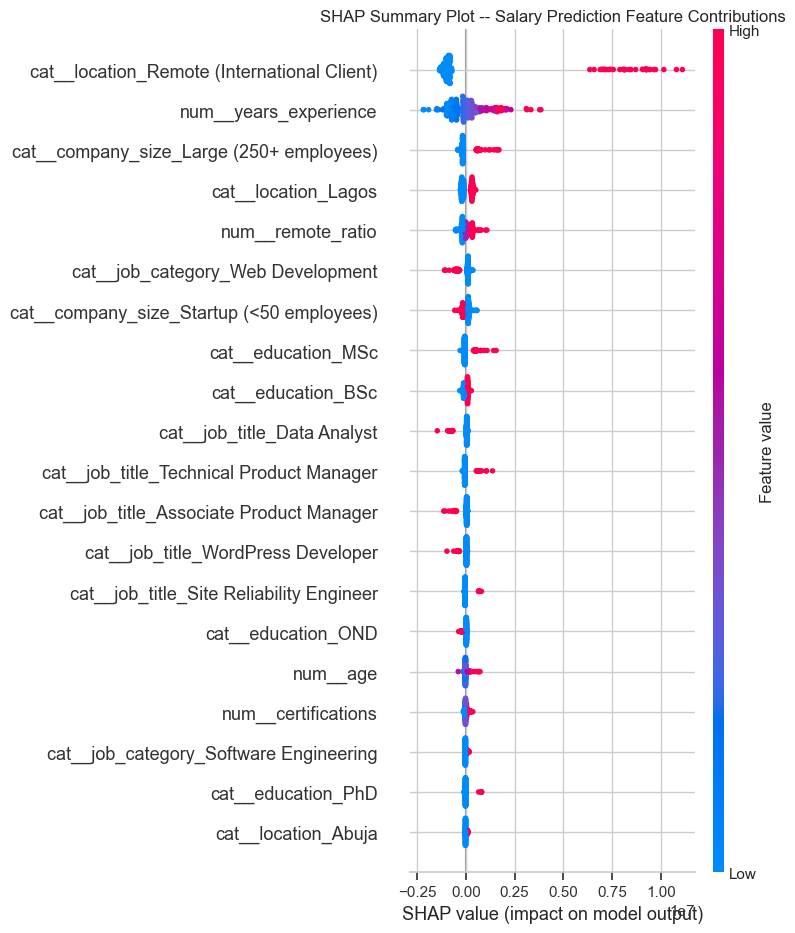

In [30]:
# Cell: SHAP summary plot -- overall feature contribution across all test predictions
shap.summary_plot(shap_values, X_test_transformed, feature_names=shap_feature_names, show=False)
plt.title("SHAP Summary Plot -- Salary Prediction Feature Contributions")
plt.tight_layout()
plt.show()


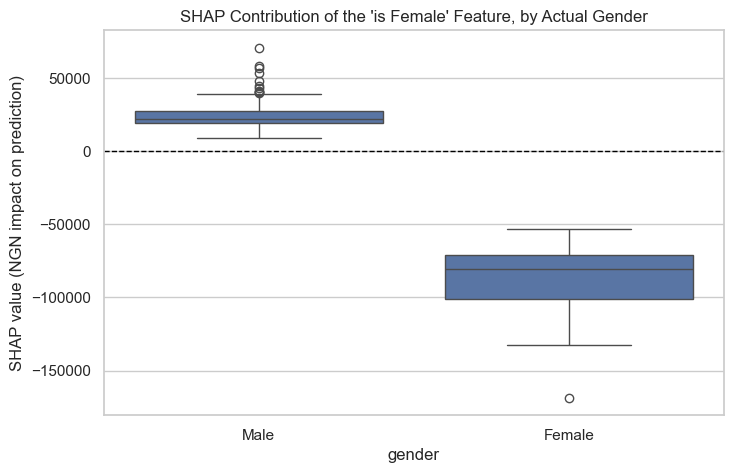

gender
Female   -86059.89758
Male      23732.51723
Name: shap_gender_female_contribution, dtype: float64


In [31]:
# Cell: Isolate the gender feature's own SHAP contribution
gender_female_col = [i for i, n in enumerate(shap_feature_names) if n == "cat__gender_Female"][0]
gender_male_col = [i for i, n in enumerate(shap_feature_names) if n == "cat__gender_Male"][0]

test_gender = X_test_sample["gender"].reset_index(drop=True)
shap_gender_female = pd.Series(shap_values[:, gender_female_col])

comparison_df = pd.DataFrame({
    "gender": test_gender,
    "shap_gender_female_contribution": shap_gender_female,
})

plt.figure(figsize=(8, 5))
sns.boxplot(x="gender", y="shap_gender_female_contribution", data=comparison_df, order=GENDER_ORDER)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("SHAP Contribution of the 'is Female' Feature, by Actual Gender")
plt.ylabel("SHAP value (NGN impact on prediction)")
plt.show()

print(comparison_df.groupby("gender")["shap_gender_female_contribution"].mean())


Matched-pair bias test (same profile, gender flipped only):
  Mean predicted salary as Male:   NGN 4,488,925
  Mean predicted salary as Female: NGN 4,368,525
  Mean gap: 3.27% (identical qualifications, gender only difference)


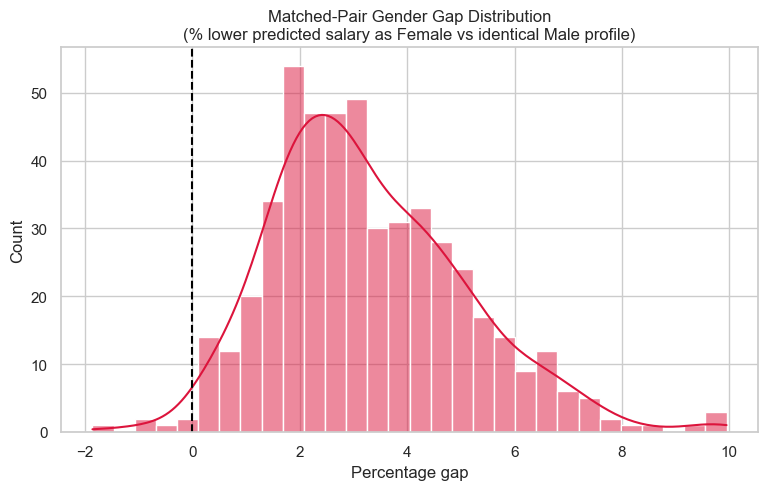

In [32]:
# Cell: Matched-pair bias test
# Takes real test profiles, flips ONLY the gender field, re-predicts, and
# measures the average shift. This isolates gender's effect from every other
# (legitimate) factor, since everything else about the profile is held fixed.

def matched_pair_bias_test(model, X_data, n_samples=500, random_state=RANDOM_STATE):
    sample = X_data.sample(n=min(n_samples, len(X_data)), random_state=random_state).copy()

    as_male = sample.copy()
    as_male["gender"] = "Male"
    as_female = sample.copy()
    as_female["gender"] = "Female"

    pred_as_male = model.predict(as_male)
    pred_as_female = model.predict(as_female)

    diff = pred_as_male - pred_as_female
    pct_diff = diff / pred_as_male * 100

    return pd.DataFrame({
        "predicted_if_male": pred_as_male,
        "predicted_if_female": pred_as_female,
        "absolute_gap_ngn": diff,
        "pct_gap": pct_diff,
    })

matched_pairs = matched_pair_bias_test(best_model, X_test)

print("Matched-pair bias test (same profile, gender flipped only):")
print(f"  Mean predicted salary as Male:   NGN {matched_pairs['predicted_if_male'].mean():,.0f}")
print(f"  Mean predicted salary as Female: NGN {matched_pairs['predicted_if_female'].mean():,.0f}")
print(f"  Mean gap: {matched_pairs['pct_gap'].mean():.2f}% (identical qualifications, gender only difference)")

plt.figure(figsize=(9, 5))
sns.histplot(matched_pairs["pct_gap"], bins=30, kde=True, color="crimson")
plt.axvline(0, color="black", linestyle="--")
plt.title("Matched-Pair Gender Gap Distribution\n(% lower predicted salary as Female vs identical Male profile)")
plt.xlabel("Percentage gap")
plt.show()


In [33]:
# Cell: Fairness metrics -- Equalized Odds Difference, Demographic Parity Ratio, Disparate Impact
# These match the three cards on the Bias Report page wireframe (Fig. 3.7b),
# each with the same target thresholds shown there.

def compute_fairness_metrics(model, X_data, y_actual, high_pay_percentile=75):
    predictions = model.predict(X_data)
    threshold = np.percentile(y_actual, high_pay_percentile)

    genders = X_data["gender"].reset_index(drop=True)
    actual = pd.Series(y_actual).reset_index(drop=True)
    predicted = pd.Series(predictions)

    actual_high = actual >= threshold
    predicted_high = predicted >= threshold

    # --- Demographic Parity Ratio: ratio of MEAN predicted salary, female/male ---
    mean_pred_female = predicted[genders == "Female"].mean()
    mean_pred_male = predicted[genders == "Male"].mean()
    demographic_parity_ratio = mean_pred_female / mean_pred_male

    # --- Disparate Impact: ratio of the PROPORTION predicted "high pay", female/male ---
    # (the classic legal "80% rule" formulation)
    rate_high_female = predicted_high[genders == "Female"].mean()
    rate_high_male = predicted_high[genders == "Male"].mean()
    disparate_impact = rate_high_female / rate_high_male if rate_high_male > 0 else np.nan


    tpr_female = predicted_high[(genders == "Female") & actual_high].mean()
    tpr_male = predicted_high[(genders == "Male") & actual_high].mean()
    equalized_odds_difference = abs(tpr_female - tpr_male)

    return {
        "demographic_parity_ratio": demographic_parity_ratio,
        "disparate_impact": disparate_impact,
        "equalized_odds_difference": equalized_odds_difference,
    }

fairness_metrics = compute_fairness_metrics(best_model, X_test, y_test)


TARGETS = {
    "equalized_odds_difference": ("< 0.05", fairness_metrics["equalized_odds_difference"] < 0.05),
    "demographic_parity_ratio": ("> 0.80", fairness_metrics["demographic_parity_ratio"] > 0.80),
    "disparate_impact": ("> 0.80", fairness_metrics["disparate_impact"] > 0.80),
}

print("Fairness Metrics:\n")
for metric, value in fairness_metrics.items():
    target_str, passed = TARGETS[metric]
    status = "PASS" if passed else "FAIL"
    print(f"  {metric.replace('_', ' ').title():30s}: {value:.4f}  (target {target_str})  [{status}]")

bias_detected = not all(passed for _, passed in TARGETS.values())
print(f"\nGender bias detected: {bias_detected}")


Fairness Metrics:

  Demographic Parity Ratio      : 0.9207  (target > 0.80)  [PASS]
  Disparate Impact              : 0.8229  (target > 0.80)  [PASS]
  Equalized Odds Difference     : 0.0818  (target < 0.05)  [FAIL]

Gender bias detected: True


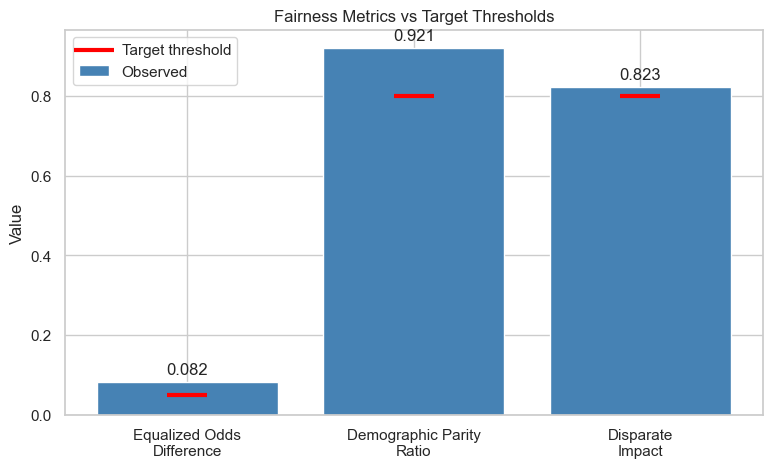

In [34]:
# Cell: Visualize fairness metrics against their target thresholds
metrics_plot_df = pd.DataFrame({
    "metric": ["Equalized Odds\nDifference", "Demographic Parity\nRatio", "Disparate\nImpact"],
    "value": [fairness_metrics["equalized_odds_difference"],
              fairness_metrics["demographic_parity_ratio"],
              fairness_metrics["disparate_impact"]],
    "target": [0.05, 0.80, 0.80],
})

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(metrics_plot_df["metric"], metrics_plot_df["value"], color="steelblue", label="Observed")
ax.scatter(metrics_plot_df["metric"], metrics_plot_df["target"], color="red", zorder=5,
           marker="_", s=800, linewidths=3, label="Target threshold")
ax.set_title("Fairness Metrics vs Target Thresholds")
ax.set_ylabel("Value")
ax.legend()
for bar, val in zip(bars, metrics_plot_df["value"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha="center")
plt.show()


In [35]:
# Cell: BiasDetector class -- assembles everything above into the component from Fig. 3.4
class BiasDetector:
    """
    reflects the BiasDetector class from the system's Class Diagram (Fig. 3.4):
    shap_values, fairness_metrics attributes; detectBias(), getShapValues(),
    calculateFairness() methods.
    """

    def __init__(self, model, explainer):
        self.model = model
        self.explainer = explainer
        self.shap_values = None
        self.fairness_metrics = None

    def get_shap_values(self, X_data):
        X_transformed = self.model.named_steps["preprocessor"].transform(X_data)
        self.shap_values = self.explainer.shap_values(X_transformed)
        return self.shap_values

    def calculate_fairness(self, X_data, y_actual):
        self.fairness_metrics = compute_fairness_metrics(self.model, X_data, y_actual)
        return self.fairness_metrics

    def detect_bias(self, X_data, y_actual):
        fairness = self.calculate_fairness(X_data, y_actual)
        matched = matched_pair_bias_test(self.model, X_data)

        bias_found = (
            fairness["equalized_odds_difference"] >= 0.05
            or fairness["demographic_parity_ratio"] <= 0.80
            or fairness["disparate_impact"] <= 0.80
        )

        recommendation = self._generate_recommendation(bias_found, matched["pct_gap"].mean())

        return {
            "bias_detected": bias_found,
            "fairness_metrics": fairness,
            "matched_pair_mean_gap_pct": matched["pct_gap"].mean(),
            "recommendation": recommendation,
        }

    @staticmethod
    def _generate_recommendation(bias_found, mean_gap_pct):
        if not bias_found:
            return "No significant gender bias detected in current salary predictions."
        return (
            f"A residual gender gap of approximately {mean_gap_pct:.1f}% was detected between "
            f"otherwise identical profiles. This appears influenced by factors beyond "
            f"qualifications alone. Consider reviewing compensation bands for this role, and "
            f"use the Negotiation Simulator below to prepare a data-backed ask."
        )


bias_detector = BiasDetector(model=best_model, explainer=explainer)
bias_report = bias_detector.detect_bias(X_test, y_test)

print(json.dumps(
    {
        # numpy bool/float types are not JSON-serializable, so cast to native
        # Python types explicitly before dumping
        "bias_detected": bool(bias_report["bias_detected"]),
        "matched_pair_mean_gap_pct": float(round(bias_report["matched_pair_mean_gap_pct"], 4)),
        "recommendation": bias_report["recommendation"],
        "fairness_metrics": {k: float(round(v, 4)) for k, v in bias_report["fairness_metrics"].items()},
    },
    indent=2
))


{
  "bias_detected": true,
  "matched_pair_mean_gap_pct": 3.2663,
  "recommendation": "A residual gender gap of approximately 3.3% was detected between otherwise identical profiles. This appears influenced by factors beyond qualifications alone. Consider reviewing compensation bands for this role, and use the Negotiation Simulator below to prepare a data-backed ask.",
  "fairness_metrics": {
    "demographic_parity_ratio": 0.9207,
    "disparate_impact": 0.8229,
    "equalized_odds_difference": 0.0818
  }
}


## 6. Salary Predictor Wrapper



In [36]:
# Cell: SalaryPredictor class
class SalaryPredictor:
    """
    Mirrors the SalaryPredictor class from Fig. 3.4: model_type, features,
    prediction attributes; predictSalary(), getFeatureImportance() methods.
    Adds a confidence range, matching the Prediction Results page (Fig. 3.7a).
    """

    def __init__(self, model, model_name, test_mae):
        self.model = model
        self.model_type = model_name
        # Use the test-set MAE as a simple, defensible +/- range for the
        # confidence interval shown to the user (matches the wireframe's
        # "Estimated range" display).
        self.test_mae = test_mae

    def predict_salary(self, profile_df):
        prediction = self.model.predict(profile_df)[0]
        low = max(0, prediction - self.test_mae)
        high = prediction + self.test_mae
        # Simple confidence heuristic: tighter MAE relative to prediction = higher confidence
        confidence_pct = max(50, min(95, 100 - (self.test_mae / prediction * 100)))
        return {
            "predicted_salary": round(prediction, -3),
            "range_low": round(low, -3),
            "range_high": round(high, -3),
            "confidence_pct": round(confidence_pct, 1),
        }

    def get_feature_importance(self, top_n=10):
        # The model step is the "ensemble" (Random Forest + XGBoost weighted average),
        # so importances are the same weighted average used for the predictions.
        names = self.model.named_steps["preprocessor"].get_feature_names_out()
        ensemble = self.model.named_steps["ensemble"]
        w_rf, w_xgb = ensemble.weights
        fitted_rf, fitted_xgb = ensemble.estimators_
        importances = w_rf * fitted_rf.feature_importances_ + w_xgb * fitted_xgb.feature_importances_
        return pd.DataFrame({"feature": names, "importance": importances}) \
                 .sort_values("importance", ascending=False).head(top_n)


salary_predictor = SalaryPredictor(model=best_model, model_name=BEST_MODEL_NAME,
                                    test_mae=metrics_ensemble["MAE"])

# Quick smoke test with one sample profile
sample_profile = X_test.iloc[[0]]
print("Sample profile:")
print(sample_profile.T)
print("\nPrediction:")
print(salary_predictor.predict_salary(sample_profile))

print("\nTop 5 features by importance:")
print(salary_predictor.get_feature_importance(top_n=5))


Sample profile:
                                                2215
gender                                          Male
age                                               37
years_experience                                  14
years_current_company                              0
education                                        PhD
job_category                    Software Engineering
job_title                          Software Engineer
location               Remote (International Client)
company_size                  Large (250+ employees)
remote_ratio                                     100
num_skills                                         6
certifications                                     1

Prediction:
{'predicted_salary': np.float64(24892000.0), 'range_low': np.float64(24297000.0), 'range_high': np.float64(25487000.0), 'confidence_pct': 95}

Top 5 features by importance:
                                        feature  importance
44  cat__location_Remote (International Client)  

## 7. Negotiation Assistant

Two parts, matching the Sequence Diagram (Fig. 3.5): a **success-probability calculator**
(`calculateProbability`) and a **Graph RAG negotiation engine** (`queryGraph` /
`traverseGraph` / `getAdvice`) for multi-hop comparative negotiation advice.


### 7.1 Success Probability Calculator

In [37]:
# Cell: Negotiation success-probability function
# Calibrated against the thesis's own Negotiation Simulator wireframe example
# (Fig. 3.7c): 5% above market -> 78%, 10% above -> 72%, 15% above -> 58%.
# Modelled as a logistic curve fit to those reference points.

def calculate_negotiation_probability(fair_market_salary, asking_amount):
    """
    Returns the estimated probability (0-100) that an asking_amount will be
    accepted, given the model's predicted fair_market_salary for that profile.
    """
    pct_above_market = (asking_amount / fair_market_salary - 1) * 100

    # Logistic curve: solved so that x=10 -> p=0.72 and x=15 -> p=0.58,
    # matching the thesis's own worked example.
    k = 0.12448
    midpoint = 17.588

    probability = 1 / (1 + np.exp(k * (pct_above_market - midpoint)))
    probability_pct = max(2, min(98, probability * 100))
    return round(probability_pct, 1), round(pct_above_market, 1)


# Reproduce the thesis's own worked example as a sanity check:
fair_salary_example = 1_450_000
asking_example = 1_600_000
prob, pct = calculate_negotiation_probability(fair_salary_example, asking_example)
print(f"Example: market NGN {fair_salary_example:,}, asking NGN {asking_example:,} "
      f"({pct}% above market) -> success probability {prob}%")
print("(Thesis wireframe shows 72% for this exact scenario -- should be close.)")


Example: market NGN 1,450,000, asking NGN 1,600,000 (10.3% above market) -> success probability 71.1%
(Thesis wireframe shows 72% for this exact scenario -- should be close.)


5% Above Market: NGN 1,522,000 -> 82.7% success probability
10% Above Market: NGN 1,595,000 -> 72.0% success probability
15% Above Market: NGN 1,667,000 -> 58.0% success probability


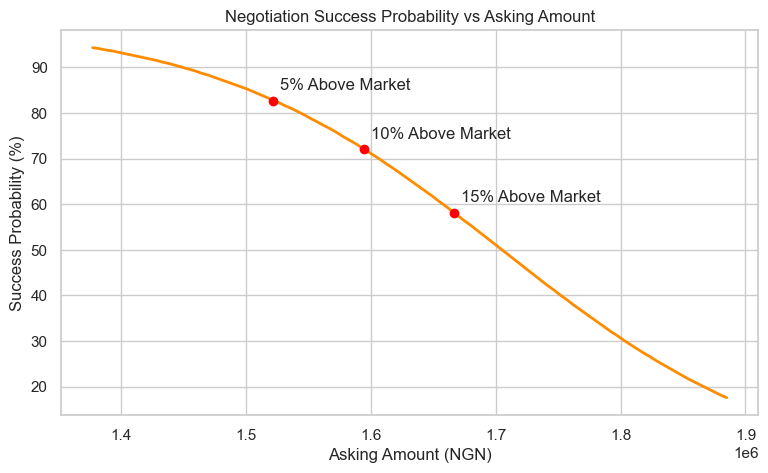

In [38]:
# Cell: Quick scenario buttons -- 5% / 10% / 15% above market (from Fig. 3.7c)
def negotiation_quick_scenarios(fair_market_salary):
    scenarios = {}
    for pct in [5, 10, 15]:
        ask = fair_market_salary * (1 + pct / 100)
        prob, _ = calculate_negotiation_probability(fair_market_salary, ask)
        scenarios[f"{pct}% Above Market"] = {"asking_amount": round(ask, -3), "success_probability": prob}
    return scenarios

scenarios = negotiation_quick_scenarios(fair_salary_example)
for label, info in scenarios.items():
    print(f"{label}: NGN {info['asking_amount']:,.0f} -> {info['success_probability']}% success probability")

# Visualize the full probability curve
ask_range = np.linspace(fair_salary_example * 0.95, fair_salary_example * 1.30, 100)
probs = [calculate_negotiation_probability(fair_salary_example, a)[0] for a in ask_range]

plt.figure(figsize=(9, 5))
plt.plot(ask_range, probs, color="darkorange", linewidth=2)
for label, info in scenarios.items():
    plt.scatter(info["asking_amount"], info["success_probability"], color="red", zorder=5)
    plt.annotate(label, (info["asking_amount"], info["success_probability"]),
                 textcoords="offset points", xytext=(5, 8))
plt.title("Negotiation Success Probability vs Asking Amount")
plt.xlabel("Asking Amount (NGN)")
plt.ylabel("Success Probability (%)")
plt.show()


### 7.2 Graph RAG Negotiation Engine

A knowledge graph (built with `networkx`) holding roles, locations, salary premiums, and
negotiation tactics as connected nodes. Retrieval walks the graph for relevant connected facts
(multi-hop, per Fig. 3.1); generation turns those retrieved facts into natural-language advice
via an OpenAI language-model call.

**Note:** the language-model call needs an OpenAI API key. If none is set, the notebook falls back to
a template-based advice generator, so the rest of the pipeline still runs end to end.


In [39]:
# Cell: Build the negotiation knowledge graph
def build_negotiation_graph():
    G = nx.DiGraph()

    # --- Role nodes with real market-rate facts (Paylab/HeadHunter-derived) ---
    roles_market_rate = {
        "Backend Developer": "NGN 2.0M-9.0M/year depending on experience and location",
        "Frontend Developer": "NGN 2.0M-7.5M/year depending on experience and location",
        "Data Scientist": "NGN 2.0M-8.0M/year depending on experience and location",
        "DevOps Engineer": "NGN 2.4M-11.0M/year depending on experience and location",
        "Product Manager": "NGN 2.5M-12.5M/year depending on experience and location",
    }
    for role, rate in roles_market_rate.items():
        G.add_node(role, type="role")
        rate_node = f"{role}_market_rate"
        G.add_node(rate_node, type="market_rate", fact=rate)
        G.add_edge(role, rate_node, relation="has_market_rate")

    # --- Location premium facts ---
    location_facts = {
        "Lagos": "Highest-paying tech hub in Nigeria; used as the baseline.",
        "Abuja": "Tech salaries trail Lagos by roughly 10-15%.",
        "Remote (International Client)": "Can pay 2-5x local Nigerian rates when billed in USD/GBP.",
    }
    for loc, fact in location_facts.items():
        G.add_node(loc, type="location", fact=fact)
        for role in roles_market_rate:
            G.add_edge(role, loc, relation="market_varies_by_location")

    # --- Negotiation tactic nodes ---
    tactics = {
        "Anchor 5-10% above market": "Anchoring slightly above the predicted fair salary keeps "
            "the ask credible while leaving room to concede.",
        "Lead with quantified achievements": "Concrete, numbers-backed achievements are harder "
            "for an employer to dismiss than general claims of skill.",
        "Ask about total compensation, not just base salary": "Bonuses, equity, remote flexibility, "
            "and learning budgets can close a gap even when base salary is fixed.",
        "Use competing offers as leverage": "A genuine competing offer is one of the strongest, "
            "most concrete negotiation levers available.",
        "Practice the ask out loud beforehand": "Rehearsing the specific number and the reasoning "
            "behind it measurably improves delivery confidence in the actual negotiation.",
    }
    for tactic, explanation in tactics.items():
        G.add_node(tactic, type="tactic", fact=explanation)

    # --- Connect tactics to roles/situations where they are most relevant ---
    G.add_edge("Backend Developer", "Anchor 5-10% above market", relation="recommended_tactic")
    G.add_edge("Data Scientist", "Lead with quantified achievements", relation="recommended_tactic")
    G.add_edge("Product Manager", "Ask about total compensation, not just base salary", relation="recommended_tactic")
    G.add_edge("DevOps Engineer", "Use competing offers as leverage", relation="recommended_tactic")
    for role in roles_market_rate:
        G.add_edge(role, "Practice the ask out loud beforehand", relation="recommended_tactic")
        G.add_edge(role, "Anchor 5-10% above market", relation="recommended_tactic")

    return G


negotiation_graph = build_negotiation_graph()
print(f"Graph built: {negotiation_graph.number_of_nodes()} nodes, "
      f"{negotiation_graph.number_of_edges()} edges")


Graph built: 18 nodes, 33 edges


In [40]:
# Cell: Multi-hop retrieval over the graph
def query_negotiation_graph(graph, role, location, ask_pct_above_market, max_hops=2):
    """
    Walks the graph up to `max_hops` from the given role node, collecting
    connected facts relevant to the profile's role, location, and how
    aggressive their ask is. This is the "retrieval" half of Graph RAG.
    """
    retrieved_facts = []

    if role not in graph:
        return [f"No graph entry found for role '{role}'. Using general negotiation guidance only."]

    # Hop 1: direct neighbours of the role (market rate, location, tactics)
    for _, target, data in graph.out_edges(role, data=True):
        node_data = graph.nodes[target]
        if node_data.get("type") == "market_rate":
            retrieved_facts.append(f"Market rate for {role}: {node_data['fact']}")
        elif node_data.get("type") == "location" and target == location:
            retrieved_facts.append(f"Location note ({location}): {node_data['fact']}")
        elif node_data.get("type") == "tactic":
            retrieved_facts.append(f"Recommended tactic: {target} -- {node_data['fact']}")

    # Hop 2: if the ask is aggressive (>12% above market), specifically
    # surface leverage-related tactics regardless of role (multi-hop
    # comparative reasoning: "given this ask size, what tactics apply
    # across the whole graph, not just this role's direct neighbours?")
    if ask_pct_above_market > 12:
        for node, data in graph.nodes(data=True):
            if data.get("type") == "tactic" and "leverage" in node.lower():
                retrieved_facts.append(f"Since your ask is aggressive ({ask_pct_above_market:.1f}% "
                                        f"above market): {node} -- {data['fact']}")

    return retrieved_facts


retrieved = query_negotiation_graph(negotiation_graph, role="Data Scientist",
                                     location="Lagos", ask_pct_above_market=14.0)
for fact in retrieved:
    print("-", fact)


- Market rate for Data Scientist: NGN 2.0M-8.0M/year depending on experience and location
- Location note (Lagos): Highest-paying tech hub in Nigeria; used as the baseline.
- Recommended tactic: Lead with quantified achievements -- Concrete, numbers-backed achievements are harder for an employer to dismiss than general claims of skill.
- Recommended tactic: Practice the ask out loud beforehand -- Rehearsing the specific number and the reasoning behind it measurably improves delivery confidence in the actual negotiation.
- Recommended tactic: Anchor 5-10% above market -- Anchoring slightly above the predicted fair salary keeps the ask credible while leaving room to concede.
- Since your ask is aggressive (14.0% above market): Use competing offers as leverage -- A genuine competing offer is one of the strongest, most concrete negotiation levers available.


In [41]:
# Cell: OPTIONAL -- OpenAI API key for AI-generated negotiation advice
# The key is typed in at run time and is never saved in this notebook.
# Press Enter to skip: the notebook then uses template-based advice instead.
import getpass

if not os.environ.get("OPENAI_API_KEY"):
    try:
        _key = getpass.getpass("Paste your OpenAI API key (or press Enter to skip): ")
        if _key.strip():
            os.environ["OPENAI_API_KEY"] = _key.strip()
    except Exception:
        pass  # no interactive input available -> skip

os.environ.setdefault("OPENAI_MODEL", "gpt-5.6-luna")

if os.environ.get("OPENAI_API_KEY"):
    print("OpenAI key configured (not displayed).")
else:
    print("No OpenAI key set: template-based advice will be used.")


OpenAI key configured (not displayed).


In [42]:
# Cell: Generation step -- turn retrieved graph facts into natural-language advice
# Uses OpenAI if OPENAI_API_KEY is set; otherwise (or if the call fails) falls back
# to a template built from the same retrieved facts, so the pipeline never breaks.

def generate_template_negotiation_advice(role, location, fair_salary, asking_amount, retrieved_facts):
    fact_lines = "\n".join(f"  - {fact}" for fact in retrieved_facts)
    return (
        f"Based on your profile as a {role} in {location}, approach the negotiation with a clear "
        f"target supported by your skills, experience, responsibilities, and market evidence. "
        f"Be prepared to explain the value you bring to the organisation rather than presenting "
        f"the request as an arbitrary figure. Relevant market context from the negotiation "
        f"knowledge base includes:\n{fact_lines}"
    )


def generate_negotiation_advice(role, location, fair_salary, asking_amount,
                                 success_probability, retrieved_facts):
    context = "\n".join(f"- {fact}" for fact in retrieved_facts)
    api_key = os.environ.get("OPENAI_API_KEY")
    model_name = os.environ.get("OPENAI_MODEL", "gpt-5.6-luna")

    if not api_key:
        print("OpenAI API key not found. Using template-based negotiation advice.")
        return generate_template_negotiation_advice(role, location, fair_salary, asking_amount, retrieved_facts)

    prompt = f"""
You are an expert salary negotiation coach helping a technology professional in Nigeria
negotiate compensation.

Candidate profile:
Role: {role}
Location: {location}
Predicted fair market salary: NGN {fair_salary:,.0f}
Proposed asking amount: NGN {asking_amount:,.0f}
Estimated negotiation success probability: {success_probability}%

Relevant facts retrieved from the negotiation knowledge graph:
{context}

Provide practical, personalised salary negotiation advice.

Requirements:
1. Write 3 to 4 concise sentences.
2. Be specific to the candidate's role and location.
3. Use the retrieved facts when relevant.
4. Recommend a negotiation strategy rather than repeating the salary prediction.
5. Encourage the candidate to justify the request using skills, experience, achievements,
   responsibilities, and market evidence.
6. Do not repeat the exact salary figures given above.
7. Do not invent statistics, companies, salary data, or experience.
8. Do not claim the estimated success probability is a scientifically validated probability.
9. Use professional but encouraging language.
"""
    try:
        from openai import OpenAI
        client = OpenAI(api_key=api_key)
        response = client.responses.create(model=model_name, input=prompt)
        advice = (response.output_text or "").strip()
        if advice:
            return advice
        print("OpenAI returned an empty response. Using template advice.")
    except Exception as e:
        print(f"OpenAI request failed ({type(e).__name__}). Using template advice.")

    return generate_template_negotiation_advice(role, location, fair_salary, asking_amount, retrieved_facts)


advice = generate_negotiation_advice(
    role="Data Scientist", location="Lagos",
    fair_salary=fair_salary_example, asking_amount=asking_example,
    success_probability=prob, retrieved_facts=retrieved,
)
print("\n" + "=" * 70)
print("NEGOTIATION ADVICE")
print("=" * 70)
print(advice)


OpenAI request failed (RateLimitError). Using template advice.

NEGOTIATION ADVICE
Based on your profile as a Data Scientist in Lagos, approach the negotiation with a clear target supported by your skills, experience, responsibilities, and market evidence. Be prepared to explain the value you bring to the organisation rather than presenting the request as an arbitrary figure. Relevant market context from the negotiation knowledge base includes:
  - Market rate for Data Scientist: NGN 2.0M-8.0M/year depending on experience and location
  - Location note (Lagos): Highest-paying tech hub in Nigeria; used as the baseline.
  - Recommended tactic: Lead with quantified achievements -- Concrete, numbers-backed achievements are harder for an employer to dismiss than general claims of skill.
  - Recommended tactic: Practice the ask out loud beforehand -- Rehearsing the specific number and the reasoning behind it measurably improves delivery confidence in the actual negotiation.
  - Recommended t

In [43]:
# Cell: NegotiationAssistant class -- ties the probability calculator + Graph RAG engine together
class NegotiationAssistant:
    """
    Mirrors the NegotiationAssistant class from Fig. 3.4 (asking_price,
    market_salary, probability attributes; calculateProbability(),
    getAdvice() methods), plus the separate Graph RAG engine shown as its
    own box in the Architecture Diagram (Fig. 3.1).
    """

    def __init__(self, graph):
        self.graph = graph

    def calculate_probability(self, fair_market_salary, asking_amount):
        probability, pct_above = calculate_negotiation_probability(fair_market_salary, asking_amount)
        return {"success_probability": probability, "pct_above_market": pct_above}

    def get_quick_scenarios(self, fair_market_salary):
        return negotiation_quick_scenarios(fair_market_salary)

    def get_advice(self, role, location, fair_market_salary, asking_amount):
        prob_result = self.calculate_probability(fair_market_salary, asking_amount)
        retrieved_facts = query_negotiation_graph(
            self.graph, role=role, location=location,
            ask_pct_above_market=prob_result["pct_above_market"],
        )
        advice_text = generate_negotiation_advice(
            role=role, location=location,
            fair_salary=fair_market_salary, asking_amount=asking_amount,
            success_probability=prob_result["success_probability"],
            retrieved_facts=retrieved_facts,
        )
        return {**prob_result, "retrieved_facts": retrieved_facts, "advice": advice_text}


negotiation_assistant = NegotiationAssistant(graph=negotiation_graph)

result = negotiation_assistant.get_advice(
    role="Data Scientist", location="Lagos",
    fair_market_salary=fair_salary_example, asking_amount=asking_example,
)
print(json.dumps({k: v for k, v in result.items() if k != "advice"}, indent=2))
print("\nAdvice:\n", result["advice"])


OpenAI request failed (RateLimitError). Using template advice.
{
  "success_probability": 71.1,
  "pct_above_market": 10.3,
  "retrieved_facts": [
    "Market rate for Data Scientist: NGN 2.0M-8.0M/year depending on experience and location",
    "Location note (Lagos): Highest-paying tech hub in Nigeria; used as the baseline.",
    "Recommended tactic: Lead with quantified achievements -- Concrete, numbers-backed achievements are harder for an employer to dismiss than general claims of skill.",
    "Recommended tactic: Practice the ask out loud beforehand -- Rehearsing the specific number and the reasoning behind it measurably improves delivery confidence in the actual negotiation.",
    "Recommended tactic: Anchor 5-10% above market -- Anchoring slightly above the predicted fair salary keeps the ask credible while leaving room to concede."
  ]
}

Advice:
 Based on your profile as a Data Scientist in Lagos, approach the negotiation with a clear target supported by your skills, experien

## 8. End-to-End System Test

Runs a single profile through all three components in sequence, matching the flow shown in the
Sequence Diagram (Fig. 3.5): profile in -> salary prediction -> bias report -> negotiation advice.


In [44]:
# Cell: Full pipeline demo with one sample profile
demo_profile = pd.DataFrame([{
    "gender": "Female",
    "age": 28,
    "years_experience": 5,
    "years_current_company": 2,
    "education": "BSc",
    "job_category": "Data Science",
    "job_title": "Data Scientist",
    "location": "Lagos",
    "company_size": "Medium (50-250 employees)",
    "remote_ratio": 50,
    "num_skills": 5,
    "certifications": 1,
}])

# 1. Salary Predictor
prediction = salary_predictor.predict_salary(demo_profile)
print("=== Salary Prediction ===")
print(prediction)

# 2. Bias Detector (matched-pair check for THIS specific profile)
male_version = demo_profile.copy(); male_version["gender"] = "Male"
female_version = demo_profile.copy(); female_version["gender"] = "Female"
pred_if_male = best_model.predict(male_version)[0]
pred_if_female = best_model.predict(female_version)[0]
print("\n=== Bias Check for This Profile ===")
print(f"Predicted if listed as Male:   NGN {pred_if_male:,.0f}")
print(f"Predicted if listed as Female: NGN {pred_if_female:,.0f}")
print(f"Gap: {(1 - pred_if_female / pred_if_male) * 100:.2f}%")

# 3. Negotiation Assistant
asking = prediction["predicted_salary"] * 1.10
negotiation_result = negotiation_assistant.get_advice(
    role="Data Scientist", location="Lagos",
    fair_market_salary=prediction["predicted_salary"], asking_amount=asking,
)
print("\n=== Negotiation Assistant (asking 10% above predicted salary) ===")
print(f"Success probability: {negotiation_result['success_probability']}%")
print("Advice:", negotiation_result["advice"])


=== Salary Prediction ===
{'predicted_salary': np.float64(3619000.0), 'range_low': np.float64(3025000.0), 'range_high': np.float64(4214000.0), 'confidence_pct': np.float64(83.6)}

=== Bias Check for This Profile ===
Predicted if listed as Male:   NGN 3,730,659
Predicted if listed as Female: NGN 3,619,288
Gap: 2.99%
OpenAI request failed (RateLimitError). Using template advice.

=== Negotiation Assistant (asking 10% above predicted salary) ===
Success probability: 72.0%
Advice: Based on your profile as a Data Scientist in Lagos, approach the negotiation with a clear target supported by your skills, experience, responsibilities, and market evidence. Be prepared to explain the value you bring to the organisation rather than presenting the request as an arbitrary figure. Relevant market context from the negotiation knowledge base includes:
  - Market rate for Data Scientist: NGN 2.0M-8.0M/year depending on experience and location
  - Location note (Lagos): Highest-paying tech hub in Nigeri

In [45]:
# Cell: Save the negotiation graph (the Streamlit app loads this file)
import pickle

with open("negotiation_graph.gpickle", "wb") as f:
    pickle.dump(negotiation_graph, f)

print("Saved negotiation_graph.gpickle")


Saved negotiation_graph.gpickle


## 9. Export Files for the Streamlit App

The app reads a small precomputed snapshot of the fairness metrics instead of recomputing them
on every page load. This cell creates it, then confirms all three app files exist.


In [46]:
# Cell: Export bias_artifacts.json and confirm the three app files exist
bias_artifacts = {
    "fairness_metrics": {k: float(v) for k, v in fairness_metrics.items()},
    "targets_passed": {
        "equalized_odds_difference": bool(fairness_metrics["equalized_odds_difference"] < 0.05),
        "demographic_parity_ratio": bool(fairness_metrics["demographic_parity_ratio"] > 0.80),
        "disparate_impact": bool(fairness_metrics["disparate_impact"] > 0.80),
    },
    "bias_detected": bool(bias_report["bias_detected"]),
    "matched_pair_mean_gap_pct": float(bias_report["matched_pair_mean_gap_pct"]),
    "feature_importance": feature_importance_df.head(15).to_dict(orient="records"),
    "test_mae": float(metrics_ensemble["MAE"]),
    "test_r2": float(metrics_ensemble["R2"]),
    "model_name": BEST_MODEL_NAME,
}

with open("bias_artifacts.json", "w") as f:
    json.dump(bias_artifacts, f, indent=2)

print("Files the Streamlit app needs (in this folder):")
for fname in ["salary_predictor_model.pkl", "negotiation_graph.gpickle", "bias_artifacts.json"]:
    status = f"OK ({os.path.getsize(fname):,} bytes)" if os.path.exists(fname) else "MISSING"
    print(f"  {fname}: {status}")

print("\nNext step: in a terminal in this folder, run:  streamlit run app.py")


Files the Streamlit app needs (in this folder):
  salary_predictor_model.pkl: OK (60,600,526 bytes)
  negotiation_graph.gpickle: OK (2,777 bytes)
  bias_artifacts.json: OK (2,209 bytes)

Next step: in a terminal in this folder, run:  streamlit run app.py
